In [16]:
#LIBRERIAS PRINCIPALES

import pandas as pd
import numpy as np

#LIBRERIAS VISUALIZACION

import matplotlib.pyplot as plt
import plotly as px
import seaborn as sns

#LIBRERIAS MACHINE LEARNING

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

#configuracion general

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

#configuracion de graficos

plt.rcParams["figure.figsize"]=(12,6)
plt.rcParams["axes.grid"]=True
plt.rcParams["font.size"]=11

In [3]:
df = pd.read_excel(r"C:\Users\jhonn\Desktop\NEOLAND\PROYECTO - COCHE\data_raw\coches_es_2026.xlsx")

display(df)

,id,source_site,seller_country,make,model,model_group,version,price_eur,previous_price_eur,price_evaluation,...,body_type,color,drive_type,doors,seats,seller_city,images_count,accident_free,first_seen_at,last_verified_at
0,mc_076a05633838,autoscout,ES,Mazda,3,Mazda3,2.0 SKYACTIV-G 88KW EVOLUTION,18990,18990.0,NaN,...,Limousine,Grau,NaN,NaN,NaN,PATERNA,21,0.0,2026-10-01 05:52:09,2026-10-06 08:55:37
1,mc_567123cacf1e,autoscout,ES,Lynk & Co,01,1,1.5T PHEV,18955,18955.0,NaN,...,SUV/4x4/Pickup,Schwarz,NaN,NaN,NaN,Sevilla,10,0.0,2026-10-01 08:32:07,2026-10-06 08:00:42
2,mc_562989b9e825,autoscout,ES,BMW,Z3 M,Z3,230i Sport,47490,47490.0,NaN,...,NaN,NaN,NaN,NaN,NaN,ALICANTE,25,0.0,2026-10-01 08:52:23,2026-10-06 07:47:06
3,mc_f8bbf7868292,autoscout,ES,Land Rover,Discovery Sport,Discovery Sport,2.0 Td4 S AWD,16761,16761.0,NaN,...,SUV/4x4/Pickup,Grau,NaN,NaN,NaN,Valencia,36,0.0,2026-10-01 09:50:35,2026-10-06 08:59:15
4,mc_54aa2a252854,autoscout,ES,Jeep,Compass,Compass,1.5 MHEV Altitude FWD DCT,23990,23990.0,NaN,...,SUV/4x4/Pickup,Rot,NaN,NaN,NaN,ZARAGOZA,36,0.0,2026-10-01 12:16:20,2026-10-06 07:59:37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99376,mc_add4c4d97004,autoscout,ES,Volkswagen,Touran,Touran,Sport 1.5 TSI 110 kW (150 CV) DSG 7 vel. 5 plazas,22071,NaN,NaN,...,Monovolumen,WeiÃƒÆ’Ã…Â¸,NaN,NaN,NaN,LAS ROZAS,29,1.0,2026-10-14 20:29:17,2026-10-15 03:11:32
99377,mc_b2f438192199,autoscout,ES,Tesla,Model 3,Model 3,Long-Range Dual Motor AWD,23790,NaN,NaN,...,Limousine,WeiÃƒÆ’Ã…Â¸,NaN,NaN,NaN,Zaragoza,35,1.0,2026-10-14 20:29:16,2026-10-15 03:11:32
99378,mc_e5cf0166eb93,autoscout,ES,SEAT,Leon,Leon,1.5 EcoTSI S&S FR 130,14790,NaN,NaN,...,Coche pequeño,Blau,NaN,NaN,NaN,Zaragoza,37,1.0,2026-10-14 20:29:15,2026-10-15 03:11:32
99379,mc_9160ba082d46,autoscout,ES,Renault,Kadjar,Kadjar,1.3 TCe GPF Zen 103kW,16240,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Mijas - Algeciras,22,NaN,2026-10-10 12:43:32,2026-10-15 03:11:32


In [3]:
df.columns
list(df.columns)

['id',
 'source_site',
 'seller_country',
 'make',
 'model',
 'model_group',
 'version',
 'price_eur',
 'previous_price_eur',
 'price_evaluation',
 'mileage_km',
 'first_registration',
 'reg_year',
 'power_hp',
 'fuel',
 'transmission',
 'body_type',
 'color',
 'drive_type',
 'doors',
 'seats',
 'seller_city',
 'images_count',
 'accident_free',
 'first_seen_at',
 'last_verified_at']

In [4]:
tipos=pd.DataFrame(df.dtypes,columns=["Tipo"])
tipos

,Tipo
id,object
source_site,object
seller_country,object
make,object
model,object
model_group,object
version,object
price_eur,int64
previous_price_eur,float64
price_evaluation,object


In [7]:
df["first_seen_at"] = pd.to_datetime(df["first_seen_at"], errors="coerce")
df["last_verified_at"] = pd.to_datetime(df["last_verified_at"], errors="coerce")

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99381 entries, 0 to 99380
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id                  99381 non-null  object        
 1   source_site         99381 non-null  object        
 2   seller_country      99381 non-null  object        
 3   make                99381 non-null  object        
 4   model               95967 non-null  object        
 5   model_group         96186 non-null  object        
 6   version             98911 non-null  object        
 7   price_eur           99381 non-null  int64         
 8   previous_price_eur  413 non-null    float64       
 9   price_evaluation    44 non-null     object        
 10  mileage_km          99381 non-null  int64         
 11  first_registration  99381 non-null  object        
 12  reg_year            99381 non-null  int64         
 13  power_hp            99381 non-null  int64     

eliminar seats, drive type, doors, price evaluation, previous price

In [4]:
duplicados = df.duplicated().sum()
print("Duplicados:",duplicados)

Duplicados: 0


In [6]:
# Eliminar columnas sin información (casi 100 % nulos) o con riesgo de leakage
cols_drop = ["seats", "drive_type", "doors", "price_evaluation", "previous_price_eur"]

df_clean = df.drop(columns=cols_drop).copy()

# Comprobaciones
print("Antes:", df.shape)         # (99381, 26)
print("Después:", df_clean.shape) # (99381, 21)

Antes: (99381, 26)
Después: (99381, 21)


In [18]:
# Tabla de decisiones de limpieza
decisiones = pd.DataFrame([
    {"que": "Eliminar drive_type", "por_que": "100 % nulos", "impacto": "-1 col"},
    {"que": "Eliminar doors, seats", "por_que": "99,99 % nulos (2 valores)", "impacto": "-2 col"},
    {"que": "Eliminar price_evaluation", "por_que": "99,96 % nulos (44 valores)", "impacto": "-1 col"},
    {"que": "Eliminar previous_price_eur", "por_que": "99,6 % nulos + riesgo de leakage", "impacto": "-1 col"},
])

In [19]:
# Convertir columnas de fecha (errors="coerce" → lo que no se pueda leer pasa a NaT)
cols_fecha = ["first_registration", "first_seen_at", "last_verified_at"]

for col in cols_fecha:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# Comprobar tipos y cuántas fechas no se han podido convertir
print(df_clean[cols_fecha].dtypes)
print(df_clean[cols_fecha].isna().sum())

first_registration    datetime64[ns]
first_seen_at         datetime64[ns]
last_verified_at      datetime64[ns]
dtype: object
first_registration    0
first_seen_at         0
last_verified_at      0
dtype: int64


In [20]:
variables_numericas = df_clean.select_dtypes(include=np.number).columns.tolist()
variables_categoricas=df_clean.select_dtypes(include="object").columns.tolist()
variables_booleanas=df_clean.select_dtypes(include="bool").columns.tolist()
variables_fecha=df_clean.select_dtypes(include="datetime").columns.tolist()



print(variables_numericas)
print(variables_categoricas)
print(variables_booleanas)
print(variables_fecha)

['price_eur', 'mileage_km', 'reg_year', 'power_hp', 'images_count', 'accident_free']
['id', 'source_site', 'seller_country', 'make', 'model', 'model_group', 'version', 'fuel', 'transmission', 'body_type', 'color', 'seller_city']
[]
['first_registration', 'first_seen_at', 'last_verified_at']


In [21]:

display(df_clean)

,id,source_site,seller_country,make,model,model_group,version,price_eur,mileage_km,first_registration,...,power_hp,fuel,transmission,body_type,color,seller_city,images_count,accident_free,first_seen_at,last_verified_at
0,mc_076a05633838,autoscout,ES,Mazda,3,Mazda3,2.0 SKYACTIV-G 88KW EVOLUTION,18990,96394,2020-06-01,...,122,Electro/Gasolina,Schaltgetriebe,Limousine,Grau,PATERNA,21,0.0,2026-10-01 05:52:09,2026-10-06 08:55:37
1,mc_567123cacf1e,autoscout,ES,Lynk & Co,01,1,1.5T PHEV,18955,75629,2023-07-01,...,261,Electro/Gasolina,Automatik,SUV/4x4/Pickup,Schwarz,Sevilla,10,0.0,2026-10-01 08:32:07,2026-10-06 08:00:42
2,mc_562989b9e825,autoscout,ES,BMW,Z3 M,Z3,230i Sport,47490,20000,2025-01-01,...,245,Benzin,Automatik,NaN,NaN,ALICANTE,25,0.0,2026-10-01 08:52:23,2026-10-06 07:47:06
3,mc_f8bbf7868292,autoscout,ES,Land Rover,Discovery Sport,Discovery Sport,2.0 Td4 S AWD,16761,104330,2019-11-01,...,150,Diesel,Automatik,SUV/4x4/Pickup,Grau,Valencia,36,0.0,2026-10-01 09:50:35,2026-10-06 08:59:15
4,mc_54aa2a252854,autoscout,ES,Jeep,Compass,Compass,1.5 MHEV Altitude FWD DCT,23990,31497,2024-02-01,...,129,Benzin,Automatik,SUV/4x4/Pickup,Rot,ZARAGOZA,36,0.0,2026-10-01 12:16:20,2026-10-06 07:59:37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99376,mc_add4c4d97004,autoscout,ES,Volkswagen,Touran,Touran,Sport 1.5 TSI 110 kW (150 CV) DSG 7 vel. 5 plazas,22071,119782,2020-06-01,...,150,Benzin,Automatik,Monovolumen,WeiÃƒÆ’Ã…Â¸,LAS ROZAS,29,1.0,2026-10-14 20:29:17,2026-10-15 03:11:32
99377,mc_b2f438192199,autoscout,ES,Tesla,Model 3,Model 3,Long-Range Dual Motor AWD,23790,87153,2020-06-01,...,441,Eléctrico,Automatik,Limousine,WeiÃƒÆ’Ã…Â¸,Zaragoza,35,1.0,2026-10-14 20:29:16,2026-10-15 03:11:32
99378,mc_e5cf0166eb93,autoscout,ES,SEAT,Leon,Leon,1.5 EcoTSI S&S FR 130,14790,88511,2018-10-01,...,129,Benzin,Schaltgetriebe,Coche pequeño,Blau,Zaragoza,37,1.0,2026-10-14 20:29:15,2026-10-15 03:11:32
99379,mc_9160ba082d46,autoscout,ES,Renault,Kadjar,Kadjar,1.3 TCe GPF Zen 103kW,16240,77830,2019-09-01,...,140,Benzin,Schaltgetriebe,NaN,NaN,Mijas - Algeciras,22,NaN,2026-10-10 12:43:32,2026-10-15 03:11:32


In [22]:
# 1. Valores únicos de las categóricas a traducir
for col in ["source_site", "seller_country", "fuel", "transmission", "body_type", "color"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))

# 2. ¿accident_free depende de la fecha del scraping?
print(pd.crosstab(df_clean["first_seen_at"].dt.date,
                  df_clean["accident_free"].fillna(-1)))   # -1 = nulo

# 3. Numéricas: las dos colas
print(df_clean[["price_eur", "mileage_km", "power_hp", "reg_year", "images_count"]]
      .describe(percentiles=[.01, .05, .95, .99]).round(0))

# 4. Ciudades: cuántas únicas antes de normalizar
print("Ciudades únicas:", df_clean["seller_city"].nunique())


--- source_site ---
source_site
autoscout    99187
Name: count, dtype: int64

--- seller_country ---
seller_country
ES    99187
Name: count, dtype: int64

--- fuel ---
fuel
Benzin               44537
Diesel               28933
Electro/Gasolina     20798
Eléctrico             2271
Elektro               1257
Gas licuado (GLP)      892
Electro/Diésel         375
Elektro/Benzin          37
unknown                 32
Otros                   19
NaN                     14
Wasserstoff              8
Super 95                 5
Strom                    3
Super Plus 98            2
Gas natural (CNG)        2
Normal/Benzin 91         1
Autogas (LPG)            1
Name: count, dtype: int64

--- transmission ---
transmission
Automatik         53763
Schaltgetriebe    45363
NaN                  49
Halbautomatik        12
Name: count, dtype: int64

--- body_type ---
body_type
NaN                  36995
SUV/4x4/Pickup       28437
Coche pequeño        12150
Limousine            11522
Monovolumen         

In [23]:
# Cuántas filas afecta cada regla (todavía no borramos nada)
reglas = {
    "mobilede":         df_clean["source_site"] != "autoscout",
    "precio > 300k":    df_clean["price_eur"] > 300_000,
    "km > 1M":          df_clean["mileage_km"] > 1_000_000,
    "km < 1000 (km0)":  df_clean["mileage_km"] < 1_000,
    "potencia <= 1":    df_clean["power_hp"] <= 1,
    "potencia == 999":  df_clean["power_hp"] == 999,
    "transmission NaN": df_clean["transmission"].isna(),
}
resumen = pd.DataFrame({
    "filas": {k: v.sum() for k, v in reglas.items()},
    "%": {k: round(v.mean() * 100, 2) for k, v in reglas.items()},
})
print(resumen)

# Revisar a mano los 20 más caros
print(df_clean.nlargest(20, "price_eur")[["make", "model_group", "version", "reg_year", "mileage_km", "price_eur"]])

                  filas     %
mobilede              0  0.00
precio > 300k       371  0.37
km > 1M               6  0.01
km < 1000 (km0)    4166  4.20
potencia <= 1       974  0.98
potencia == 999       8  0.01
transmission NaN     49  0.05
               make model_group         version  reg_year  mileage_km  \
92188       Ferrari     Daytona             SP3      2023         700   
69733       Ferrari     Daytona             SP3      2025         200   
54538       Ferrari     Daytona             SP3      2025         283   
14866       Ferrari     Daytona             SP3      2023         100   
67991       Ferrari         F40             F80      2026         100   
69472  Aston Martin    Valkyrie             NaN      2024           0   
70586    Koenigsegg       Jesko          Attack      2026         100   
31765    Koenigsegg       Jesko          Attack      2026          50   
49594       Bugatti      Chiron           Sport      2021        1800   
70853       Bugatti      Chiro

In [24]:
# --- Parámetros de alcance (fijos, de negocio) ---
PRECIO_MAX = 150_000
KM_MIN = 1_000
KM_MAX = 1_000_000

n_inicial = len(df_clean)

def registrar(que, por_que, n_antes, n_despues):
    """Añade una fila a la tabla de decisiones."""
    decisiones.loc[len(decisiones)] = [que, por_que, f"-{n_antes - n_despues} filas"]

# 1. Solo autoscout
n = len(df_clean)
df_clean = df_clean[df_clean["source_site"] == "autoscout"]
registrar("Filtrar a autoscout", "mobilede = 0,2 %, otro portal", n, len(df_clean))

# 2. Precio máximo (alcance)
n = len(df_clean)
df_clean = df_clean[df_clean["price_eur"] <= PRECIO_MAX]
registrar(f"Precio <= {PRECIO_MAX}", "Hiperdeportivos: otro mercado", n, len(df_clean))

# 3. Km fuera de rango
n = len(df_clean)
df_clean = df_clean[df_clean["mileage_km"].between(KM_MIN, KM_MAX)]
registrar(f"Km entre {KM_MIN} y {KM_MAX}", "Km0 (alcance) + imposibles", n, len(df_clean))

# 4. Transmission nula
n = len(df_clean)
df_clean = df_clean.dropna(subset=["transmission"])
registrar("Eliminar transmission NaN", "< 0,1 %", n, len(df_clean))

# 5. Potencia imposible → NaN (se imputa después del split)
mask_pot = (df_clean["power_hp"] <= 1) | (df_clean["power_hp"] == 999)
df_clean.loc[mask_pot, "power_hp"] = np.nan
decisiones.loc[len(decisiones)] = ["power_hp <= 1 o 999 → NaN",
                                   "Faltante codificado como 0/1/999",
                                   f"{mask_pot.sum()} valores a imputar tras split"]

# 6. Columnas constantes o no fiables
df_clean = df_clean.drop(columns=["source_site", "seller_country", "accident_free"])
decisiones.loc[len(decisiones)] = ["Eliminar source_site, seller_country, accident_free",
                                   "Constantes / artefacto del scraping", "-3 col"]

print(f"Filas: {n_inicial} → {len(df_clean)} ({(1 - len(df_clean)/n_inicial)*100:.1f} % eliminado)")
print(df_clean.shape)
decisiones

Filas: 99187 → 94294 (4.9 % eliminado)
(94294, 18)


,que,por_que,impacto
0,Eliminar drive_type,100 % nulos,-1 col
1,"Eliminar doors, seats","99,99 % nulos (2 valores)",-2 col
2,Eliminar price_evaluation,"99,96 % nulos (44 valores)",-1 col
3,Eliminar previous_price_eur,"99,6 % nulos + riesgo de leakage",-1 col
4,Filtrar a autoscout,"mobilede = 0,2 %, otro portal",-0 filas
5,Precio <= 150000,Hiperdeportivos: otro mercado,-987 filas
6,Km entre 1000 y 1000000,Km0 (alcance) + imposibles,-3861 filas
7,Eliminar transmission NaN,"< 0,1 %",-45 filas
8,power_hp <= 1 o 999 → NaN,Faltante codificado como 0/1/999,730 valores a imputar tras split
9,"Eliminar source_site, seller_country, accident...",Constantes / artefacto del scraping,-3 col


In [25]:
# --- FUEL ---
def agrupar_fuel(x):
    if pd.isna(x):
        return "Otros"
    x = x.lower()
    if "diesel" in x or "diésel" in x:
        return "Híbrido diésel" if ("elektro" in x or "electro" in x) else "Diésel"
    if "elektro" in x or "electro" in x or "hybrid" in x:
        # "Elektro" o "Eléctrico" solos = eléctrico puro; con gasolina = híbrido
        if x in ["elektro", "eléctrico"]:
            return "Eléctrico"
        return "Híbrido gasolina"
    if x in ["eléctrico", "strom"]:
        return "Eléctrico"
    if "benzin" in x or "super" in x:
        return "Gasolina"
    if "gas" in x or "lpg" in x or "glp" in x or "cng" in x:
        return "Gas"
    return "Otros"   # Wasserstoff, unknown, Otros

df_clean["fuel"] = df_clean["fuel"].apply(agrupar_fuel)

# --- TRANSMISSION ---
df_clean["transmission"] = df_clean["transmission"].map({
    "Automatik": "Automático",
    "Halbautomatik": "Automático",
    "Schaltgetriebe": "Manual",
})

# --- BODY_TYPE ---
def agrupar_body(x):
    if pd.isna(x):
        return "Desconocido"
    x = x.lower()
    if x.startswith("coup") or x == "sportscar":
        return "Coupé"          # captura todas las variantes con encoding roto
    mapa = {
        "suv/4x4/pickup": "SUV", "offroad": "SUV",
        "coche pequeño": "Pequeño", "smallcar": "Pequeño",
        "limousine": "Berlina",
        "kombi": "Familiar", "estatecar": "Familiar",
        "monovolumen": "Monovolumen",
        "furgonetas camper": "Furgoneta", "transporter": "Furgoneta", "van": "Furgoneta",
        "cabriolet": "Cabrio", "cabrio": "Cabrio",
    }
    return mapa.get(x, "Otros")

df_clean["body_type"] = df_clean["body_type"].apply(agrupar_body)

# --- COLOR ---
def agrupar_color(x):
    if pd.isna(x):
        return "Desconocido"
    x = x.lower()
    if "wei" in x:                          return "Blanco"
    if x.startswith("grau"):                return "Gris"
    if x.startswith("gr"):                  return "Verde"   # Grün y variantes rotas
    if x.startswith("schwarz"):             return "Negro"
    if x.startswith("blau"):                return "Azul"
    if x.startswith("rot") or "burdeos" in x: return "Rojo"
    if "silber" in x or "plateado" in x:    return "Plata"
    if x.startswith(("braun", "marr", "beige", "bronce", "gold")): return "Marrón/Beige"
    if x.startswith(("gelb", "orange")):    return "Amarillo/Naranja"
    return "Otros"

df_clean["color"] = df_clean["color"].apply(agrupar_color)

# --- Comprobación ---
for col in ["fuel", "transmission", "body_type", "color"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))


--- fuel ---
fuel
Gasolina            42215
Diésel              28281
Híbrido gasolina    19443
Eléctrico            3090
Gas                   826
Híbrido diésel        369
Otros                  70
Name: count, dtype: int64

--- transmission ---
transmission
Automático    50050
Manual        44244
Name: count, dtype: int64

--- body_type ---
body_type
Desconocido    34881
SUV            27170
Pequeño        11634
Berlina        11069
Furgoneta       3149
Monovolumen     2572
Familiar        2387
Coupé            935
Cabrio           460
Otros             37
Name: count, dtype: int64

--- color ---
color
Desconocido         38253
Blanco              19482
Gris                13785
Negro                7217
Azul                 6586
Rojo                 4940
Verde                1247
Amarillo/Naranja     1113
Plata                 836
Marrón/Beige          835
Name: count, dtype: int64


In [26]:
pd.crosstab(df_clean["first_seen_at"].dt.date,
            df_clean["body_type"] == "Desconocido", normalize="index").round(2)

body_type,False,True
first_seen_at,,
2026-10-01,0.96,0.04
2026-10-02,1.00,0.00
2026-10-03,1.00,0.00
2026-10-04,1.00,0.00
2026-10-05,1.00,0.00
2026-10-06,1.00,0.00
2026-10-07,1.00,0.00
2026-10-09,1.00,0.00
2026-10-10,0.50,0.50


In [28]:
conocidos = df_clean[df_clean["body_type"] != "Desconocido"]

# % de anuncios cuya carrocería coincide con la más frecuente de su modelo
moda_modelo = conocidos.groupby("model_group")["body_type"].agg(lambda s: s.mode()[0])
acierto = (conocidos["body_type"] == conocidos["model_group"].map(moda_modelo)).mean()
print(f"Coincidencia con la moda del modelo: {acierto:.1%}")

Coincidencia con la moda del modelo: 74.7%


In [29]:
# Filas donde la carrocería NO coincide con la moda de su modelo
conocidos = conocidos.assign(moda=conocidos["model_group"].map(moda_modelo))
fallos = conocidos[conocidos["body_type"] != conocidos["moda"]]

# ¿Entre qué categorías se confunde?
print(pd.crosstab(fallos["body_type"], fallos["moda"]))

# ¿Cuánto del fallo es por model_group nulo?
print("Fallos por model_group NaN:", fallos["moda"].isna().sum(), "de", len(fallos))

moda         Berlina  Cabrio  Coupé  Familiar  Furgoneta  Monovolumen  \
body_type                                                               
Berlina            0       0     39       111          4           25   
Cabrio           298       0     75         0          3            1   
Coupé            267       9      0         1          0            1   
Familiar         852       0     22         0         37           89   
Furgoneta         21       0      2        21          0          344   
Monovolumen       91       0     86         5         89            0   
Otros             10       0      0         2         12            1   
Pequeño         2229       9     10        17          1            6   
SUV              196       0     36        17          1           53   

moda         Pequeño   SUV  
body_type                   
Berlina         4286  1403  
Cabrio             5    34  
Coupé              5   108  
Familiar         925    29  
Furgoneta         41  

In [30]:
grupos = {
    "Berlina": "Turismo", "Pequeño": "Turismo", "Familiar": "Turismo",
    "SUV": "SUV",
    "Monovolumen": "Monovolumen/Furgoneta", "Furgoneta": "Monovolumen/Furgoneta",
    "Coupé": "Deportivo", "Cabrio": "Deportivo",
    "Otros": "Otros",
}
conocidos = conocidos.assign(body_grupo=conocidos["body_type"].map(grupos))

# Solo filas con model_group (las NaN no se pueden imputar por modelo)
con_modelo = conocidos.dropna(subset=["model_group"])
moda_grupo = con_modelo.groupby("model_group")["body_grupo"].agg(lambda s: s.mode()[0])
acierto = (con_modelo["body_grupo"] == con_modelo["model_group"].map(moda_grupo)).mean()
print(f"Coincidencia con 4 categorías: {acierto:.1%}")

Coincidencia con 4 categorías: 93.3%


In [31]:
grupos = {
    "Berlina": "Turismo", "Pequeño": "Turismo", "Familiar": "Turismo",
    "SUV": "SUV",
    "Monovolumen": "Monovolumen/Furgoneta", "Furgoneta": "Monovolumen/Furgoneta",
    "Coupé": "Deportivo", "Cabrio": "Deportivo",
    "Otros": "Otros",
}
# "Desconocido" no está en el diccionario → .map() lo deja como NaN (lo que queremos)
df_clean["body_grupo"] = df_clean["body_type"].map(grupos)
df_clean = df_clean.drop(columns=["body_type"])

print(df_clean["body_grupo"].value_counts(dropna=False))

decisiones.loc[len(decisiones)] = [
    "body_type → body_grupo (4 categorías)",
    "Nulos desde 10-oct (artefacto); 93,3 % coincide con la moda por model_group",
    "NaN se imputan con moda por model_group tras split (fit en train)"]

body_grupo
NaN                      34881
SUV                      27170
Turismo                  25090
Monovolumen/Furgoneta     5721
Deportivo                 1395
Otros                       37
Name: count, dtype: int64


In [32]:
# 1. ¿El color también es artefacto del scraping?
print(pd.crosstab(df_clean["first_seen_at"].dt.date,
                  df_clean["color"] == "Desconocido", normalize="index").round(2))

# 2. ¿Son comparables los lotes antes y después del 10 de octubre?
lote = np.where(df_clean["first_seen_at"] < "2026-10-10", "1-9 oct", "10-14 oct")
print(df_clean.groupby(lote)[["price_eur", "mileage_km", "reg_year", "power_hp"]].median())
print(pd.Series(lote).value_counts())

# 3. Marca y modelo
print(df_clean[["make", "model", "model_group"]].isna().sum())
print(df_clean[["make", "model", "model_group"]].nunique())
mask = df_clean["model_group"].isna() & df_clean["model"].notna()
print("model_group rellenables con model:", mask.sum())
print(df_clean["make"].value_counts().to_string())

color          False  True 
first_seen_at              
2026-10-01      0.94   0.06
2026-10-02      0.96   0.04
2026-10-03      0.98   0.02
2026-10-04      0.96   0.04
2026-10-05      0.97   0.03
2026-10-06      0.98   0.02
2026-10-07      0.97   0.03
2026-10-09      0.92   0.08
2026-10-10      0.47   0.53
2026-10-11      0.50   0.50
2026-10-12      0.57   0.43
2026-10-13      0.45   0.55
2026-10-14      0.47   0.53
           price_eur  mileage_km  reg_year  power_hp
1-9 oct      17500.0     71125.0    2022.0     131.0
10-14 oct    18990.0     70343.5    2022.0     136.0
10-14 oct    73072
1-9 oct      21222
Name: count, dtype: int64
make              0
model          3230
model_group    2823
dtype: int64
make            95
model          940
model_group    667
dtype: int64
model_group rellenables con model: 19
make
Mercedes-Benz      10265
Peugeot             9980
Renault             8140
Volkswagen          7222
Ford                5521
Citroen             5468
BMW                 5

In [33]:
n = len(df_clean)

# 1. Fuera color y model
df_clean = df_clean.drop(columns=["color", "model"])

# 2. Unificar marcas
mapa_marcas = {
    "Citroën": "Citroen",
    "Smart": "smart",
    "KGM / SsangYong": "SsangYong", "KGM": "SsangYong",
    "Sonstige": "Otros",
}
df_clean["make"] = df_clean["make"].replace(mapa_marcas)

# 3. Fuera marcas que no son turismos
fuera_alcance = ["Iveco", "MAN", "Caravans-Wohnm", "Silence"]
df_clean = df_clean[~df_clean["make"].isin(fuera_alcance)]

# 4. Fuera filas sin model_group
df_clean = df_clean.dropna(subset=["model_group"])

print(f"{n} → {len(df_clean)} filas (-{n - len(df_clean)})")
print("Marcas únicas:", df_clean["make"].nunique())

decisiones.loc[len(decisiones)] = ["Eliminar color", "Nulos desde 10-oct (artefacto), no imputable", "-1 col"]
decisiones.loc[len(decisiones)] = ["Eliminar model (se usa model_group)", "Más limpio y menos cardinalidad", "-1 col"]
decisiones.loc[len(decisiones)] = ["Unificar marcas", "Citroën/Citroen, Smart, KGM/SsangYong", "0 filas"]
decisiones.loc[len(decisiones)] = ["Eliminar Iveco, MAN, caravanas, Silence", "No son turismos (alcance)", "ver recuento"]
decisiones.loc[len(decisiones)] = ["Eliminar model_group NaN", "3 %, variable clave, no imputable", "ver recuento"]

94294 → 91446 filas (-2848)
Marcas únicas: 86


In [34]:
decisiones.loc[len(decisiones) - 2, "impacto"] = "-2848 filas (junto con la siguiente)"
decisiones.loc[len(decisiones) - 1, "impacto"] = "-2848 filas (junto con la anterior)"

In [35]:
es_hibrido = df_clean["fuel"].str.startswith("Híbrido")
v = df_clean["version"].fillna("").str.lower()

# Palabras clave (regex: | = "o")
phev_kw = r"phev|plug-in|plug in|enchufable|e-hybrid|ehybrid|4xe|\bgte\b|tfsi ?e\b|e-tense|\bt8\b|recharge"
mhev_kw = r"mhev|mild|48v|microh|\betsi\b|e-tsi|mhybrid"

df_clean["tipo_hibrido"] = "No híbrido"
df_clean.loc[es_hibrido, "tipo_hibrido"] = "HEV"
df_clean.loc[es_hibrido & v.str.contains(mhev_kw), "tipo_hibrido"] = "MHEV"
df_clean.loc[es_hibrido & v.str.contains(phev_kw), "tipo_hibrido"] = "PHEV"   # va última: si dudas, gana PHEV

print(df_clean["tipo_hibrido"].value_counts())

# Validación: las 20 versiones más frecuentes de cada tipo
for t in ["HEV", "MHEV", "PHEV"]:
    print(f"\n--- {t} ---")
    print(df_clean.loc[df_clean["tipo_hibrido"] == t, "version"].value_counts().head(20))

tipo_hibrido
No híbrido    71666
HEV           12772
MHEV           3583
PHEV           3425
Name: count, dtype: int64

--- HEV ---
version
Dolcevita 1.0 Hybrid 51KW (70 CV)      506
125H Advance                           364
e                                      252
120H Active Tech                       146
125H Active                            136
de 4MATIC                              110
180H Advance                           110
120H 1.5 Active Plus                   102
d                                       95
250e                                    90
140H Advance                            88
1.2 E-Tech Híbrido Techno 146kW         83
120H 1.5 Active Tech                    83
Club 1.0 Hybrid 51KW (70 CV)            79
1.2 full hybrid e-tech Techno 146kW     76
esprit Alpine E-Tech 105kW (145CV)      74
xDrive25eA                              74
Connect 1.0 Hybrid 51KW (70 CV)         72
Sedan                                   71
Hatchback 5-Door                        67


In [36]:
# Reglas extra (se aplican encima de las anteriores)
# PHEV: Mercedes "e"/"de" y BMW "25e", "330e", "225xe", "xDrive25eA"
phev_extra = r"^e$|^de\b|\d+x?ea?\b"
# MHEV: Fiat 1.0 Hybrid (500 / Panda)
mhev_fiat = (df_clean["make"] == "Fiat") & v.str.contains(r"1\.0 hybrid")

df_clean.loc[es_hibrido & mhev_fiat, "tipo_hibrido"] = "MHEV"
df_clean.loc[es_hibrido & v.str.contains(phev_extra), "tipo_hibrido"] = "PHEV"

print(df_clean["tipo_hibrido"].value_counts())

# Validación por marca: ¿quién queda en HEV?
hev = df_clean[df_clean["tipo_hibrido"] == "HEV"]
print(hev["make"].value_counts().head(15))

# Los "d" dudosos
print(df_clean.loc[es_hibrido & (v == "d"), ["make", "model_group", "fuel", "power_hp"]].value_counts().head(10))

tipo_hibrido
No híbrido    71666
HEV           10545
PHEV           4730
MHEV           4505
Name: count, dtype: int64
make
Toyota           3299
Renault          1423
Mercedes-Benz    1129
Kia               637
Peugeot           552
Hyundai           534
Lexus             529
BMW               501
Citroen           298
Audi              270
Fiat              195
Volvo             155
Honda             137
Ford              122
Mazda             110
Name: count, dtype: int64
make           model_group  fuel              power_hp
Mercedes-Benz  C-Class      Híbrido gasolina  200.0       57
                                              163.0       16
                            Híbrido diésel    199.0        8
                            Híbrido gasolina  199.0        5
                                              265.0        4
               E-Class      Híbrido diésel    197.0        4
               S-Class      Híbrido gasolina  313.0        1
Name: count, dtype: int64


In [37]:
# Marcas cuyo "híbrido" sin más etiqueta es casi siempre micro-híbrido
marcas_mhev = ["Mercedes-Benz", "BMW", "Audi", "Peugeot", "Citroen", "Opel",
               "DS Automobiles", "Volvo", "Mazda", "Fiat", "Suzuki", "Jeep", "Alfa Romeo"]

mask = (df_clean["tipo_hibrido"] == "HEV") & df_clean["make"].isin(marcas_mhev)
df_clean.loc[mask, "tipo_hibrido"] = "MHEV"
print("Reasignados a MHEV:", mask.sum())
print(df_clean["tipo_hibrido"].value_counts())

# Validación con sentido de negocio: precio y potencia medianos por tipo
print(df_clean.groupby("tipo_hibrido")[["price_eur", "power_hp", "reg_year"]].median())

decisiones.loc[len(decisiones)] = [
    "Crear tipo_hibrido (No/MHEV/HEV/PHEV) desde version",
    "'Híbrido' del portal mezcla 3 tecnologías con precios distintos",
    "Regex + heurística por marca; precisión no perfecta (limitación)"]

Reasignados a MHEV: 3285
tipo_hibrido
No híbrido    71666
MHEV           7790
HEV            7260
PHEV           4730
Name: count, dtype: int64
              price_eur  power_hp  reg_year
tipo_hibrido                               
HEV             23490.0     143.0    2022.0
MHEV            19990.0     140.0    2023.0
No híbrido      17490.0     131.0    2022.0
PHEV            27985.0     245.0    2022.0


In [38]:
df_clean = df_clean.drop(columns=["version"])
decisiones.loc[len(decisiones)] = ["Eliminar version", "Ya usada para tipo_hibrido; cardinalidad muy alta", "-1 col"]

In [39]:
import unicodedata

def normalizar_texto(x):
    """Mayúsculas, sin tildes, sin paréntesis, primera parte si hay ' - ' o '/'."""
    if pd.isna(x):
        return np.nan
    x = str(x).split(" - ")[0].split("/")[0]       # "Mijas - Algeciras" → "Mijas"
    x = x.split("(")[0]                            # "Rozas (Las)" → "Rozas"
    x = unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode("ascii")  # quita tildes
    return x.upper().strip()

df_clean["ciudad_norm"] = df_clean["seller_city"].apply(normalizar_texto)

print("Únicas antes:", df_clean["seller_city"].nunique())
print("Únicas después:", df_clean["ciudad_norm"].nunique())
print(df_clean["ciudad_norm"].value_counts().head(30))

Únicas antes: 2040
Únicas después: 1443
ciudad_norm
SEVILLA                       8040
MALAGA                        4779
MADRID                        4399
ALICANTE                      4082
PATERNA                       3971
SAN SEBASTIAN DE LOS REYES    3134
VALENCIA                      2347
LAS PALMAS DE GRAN CANARIA    2282
LAS ROZAS                     2262
MURCIA                        2202
SANT ANDREU                   2151
L'HOSPITALET DE LLOBREGAT     2083
OVIEDO                        2007
SABADELL                      1938
ZARAGOZA                      1276
LA LAGUNA                     1268
LEGANES                       1113
BARCELONA                     1112
SANT ADRIA DE BESOS            989
MASSANASSA                     952
ALCALA DE GUADAIRA             830
SEDAVI                         763
CORDOBA                        673
OLIAS DEL REY                  661
PARLA                          648
SANTA CRUZ DE TENERIFE         590
GRANADA                        531
MAR

In [40]:
ciudad_a_provincia = {
    # Madrid
    "MADRID": "Madrid", "SAN SEBASTIAN DE LOS REYES": "Madrid", "LAS ROZAS": "Madrid",
    "LEGANES": "Madrid", "PARLA": "Madrid", "ALCORCON": "Madrid",
    # Barcelona
    "BARCELONA": "Barcelona", "SANT ANDREU": "Barcelona", "L'HOSPITALET DE LLOBREGAT": "Barcelona",
    "HOSPITALET DE LLOBREGAT L": "Barcelona", "SABADELL": "Barcelona", "SANT ADRIA DE BESOS": "Barcelona",
    # Valencia
    "VALENCIA": "Valencia", "PATERNA": "Valencia", "MASSANASSA": "Valencia", "SEDAVI": "Valencia",
    # Andalucía
    "SEVILLA": "Sevilla", "ALCALA DE GUADAIRA": "Sevilla",
    "MALAGA": "Málaga", "MARBELLA": "Málaga",
    "CORDOBA": "Córdoba", "GRANADA": "Granada",
    # Resto
    "ALICANTE": "Alicante", "MURCIA": "Murcia", "OVIEDO": "Asturias", "ZARAGOZA": "Zaragoza",
    "OLIAS DEL REY": "Toledo",
    "LAS PALMAS DE GRAN CANARIA": "Las Palmas",
    "LA LAGUNA": "Santa Cruz de Tenerife", "SANTA CRUZ DE TENERIFE": "Santa Cruz de Tenerife",
}

df_clean["provincia"] = df_clean["ciudad_norm"].map(ciudad_a_provincia)
print(f"Cobertura: {df_clean['provincia'].notna().mean():.1%}")

Cobertura: 64.0%


In [41]:
sin_prov = df_clean.loc[df_clean["provincia"].isna(), "ciudad_norm"].value_counts()
print(sin_prov.head(40))

ciudad_norm
BURGOS                   420
EL PRAT DE LLOBREGAT     388
ALCALA DE HENARES        387
ELCHE                    380
JEREZ DE LA FRONTERA     367
ARANJUEZ                 364
ALPEDRETE                348
TORREJON DE ARDOZ        348
ARROYOMOLINOS            341
TERRASSA                 341
ARGANDA DEL REY          341
LUGO                     335
PALMA DE MALLORCA        335
ROZAS DE PUERTO REAL     325
TOLEDO                   325
MAJADAHONDA              320
VIGO                     320
POZUELO DE ALARCON       319
FUENLABRADA              310
PINTO                    303
MOSTOLES                 301
VALLADOLID               291
COLLADO VILLALBA         291
PALENCIA                 289
JAEN                     272
LOGRONO                  272
RIVAS VACIAMADRID        264
DONOSTI                  254
ESPINARDO                254
ZARANDONA                251
SANT BOI DE LLOBREGAT    247
GIJON                    246
RIVAS-VACIAMADRID        242
ALCOBENDAS               240
BA

In [42]:
ciudad_a_provincia.update({
    # Madrid
    "ALCALA DE HENARES": "Madrid", "ARANJUEZ": "Madrid", "ALPEDRETE": "Madrid",
    "TORREJON DE ARDOZ": "Madrid", "ARROYOMOLINOS": "Madrid", "ARGANDA DEL REY": "Madrid",
    "ROZAS DE PUERTO REAL": "Madrid", "MAJADAHONDA": "Madrid", "POZUELO DE ALARCON": "Madrid",
    "FUENLABRADA": "Madrid", "PINTO": "Madrid", "MOSTOLES": "Madrid",
    "COLLADO VILLALBA": "Madrid", "RIVAS VACIAMADRID": "Madrid", "RIVAS-VACIAMADRID": "Madrid",
    "ALCOBENDAS": "Madrid",
    # Barcelona
    "EL PRAT DE LLOBREGAT": "Barcelona", "TERRASSA": "Barcelona", "SANT BOI DE LLOBREGAT": "Barcelona",
    "MANRESA": "Barcelona", "GRANOLLERS": "Barcelona",
    # Resto
    "BURGOS": "Burgos", "ELCHE": "Alicante", "JEREZ DE LA FRONTERA": "Cádiz",
    "LUGO": "Lugo", "PALMA DE MALLORCA": "Baleares", "TOLEDO": "Toledo",
    "VIGO": "Pontevedra", "VALLADOLID": "Valladolid", "PALENCIA": "Palencia",
    "JAEN": "Jaén", "LOGRONO": "La Rioja", "DONOSTI": "Gipuzkoa",
    "ESPINARDO": "Murcia", "ZARANDONA": "Murcia",          # pedanías de Murcia
    "GIJON": "Asturias", "BADAJOZ": "Badajoz", "GIRONA": "Girona",
    "SANTANDER": "Cantabria",
    "LAS CHAFIRAS": "Santa Cruz de Tenerife",              # San Miguel de Abona (Tenerife)
})

df_clean["provincia"] = df_clean["ciudad_norm"].map(ciudad_a_provincia)
print(f"Cobertura: {df_clean['provincia'].notna().mean():.1%}")
print(df_clean.loc[df_clean["provincia"].isna(), "ciudad_norm"].value_counts().head(40))

Cobertura: 77.1%
ciudad_norm
QUART DE POBLET            199
ZARATAN                    195
GETAFE                     195
IURRETA                    191
A CORUNA                   188
TELDE                      184
ELX                        183
UBEDA                      178
SANTIAGO DE COMPOSTELA     176
SANT CUGAT DEL VALLES      176
CASTELLON                  173
UTRERA                     169
HUELVA                     168
MATARO                     166
JEREZ                      164
CARTAGENA                  162
BADALONA                   161
ESTEPONA                   161
BADAL                      160
MIJAS                      159
SANT VICENT DEL RASPEIG    159
ALZIRA                     159
TARRAGONA                  154
ALBACETE                   153
ERANDIO                    149
BARBERA DEL VALLES         147
TERRASA                    143
SAN FERNANDO DE HENARES    143
BILBAO                     141
TALAVERA DE LA REINA       141
REUS                       141
ALMENDRALE

In [43]:
ciudad_a_provincia.update({
    # Madrid
    "GETAFE": "Madrid", "SAN FERNANDO DE HENARES": "Madrid",
    # Barcelona
    "SANT CUGAT DEL VALLES": "Barcelona", "MATARO": "Barcelona", "BADALONA": "Barcelona",
    "BARBERA DEL VALLES": "Barcelona", "TERRASA": "Barcelona",
    "BADAL": "Barcelona",                    # calle/barrio de Barcelona (Sants) — dudoso
    # Valencia / Alicante / Castellón
    "QUART DE POBLET": "Valencia", "ALZIRA": "Valencia",
    "ELX": "Alicante", "SANT VICENT DEL RASPEIG": "Alicante",
    "CASTELLON": "Castellón",
    # Andalucía
    "UBEDA": "Jaén", "UTRERA": "Sevilla", "DOS HERMANAS": "Sevilla",
    "HUELVA": "Huelva", "JEREZ": "Cádiz",
    "ESTEPONA": "Málaga", "MIJAS": "Málaga", "VELEZ": "Málaga",   # Vélez-Málaga — dudoso
    "ALMERIA": "Almería", "HUERCAL DE ALMERIA": "Almería", "ATARFE": "Granada",
    # Galicia / Norte
    "A CORUNA": "A Coruña", "SANTIAGO DE COMPOSTELA": "A Coruña",
    "IURRETA": "Bizkaia", "ERANDIO": "Bizkaia", "BILBAO": "Bizkaia",
    # Resto
    "ZARATAN": "Valladolid", "ASTORGA": "León",
    "TELDE": "Las Palmas", "CARTAGENA": "Murcia",
    "TARRAGONA": "Tarragona", "REUS": "Tarragona",
    "ALBACETE": "Albacete", "TALAVERA DE LA REINA": "Toledo",
    "ALMENDRALEJO": "Badajoz", "MERIDA": "Badajoz", "CACERES": "Cáceres",
})

df_clean["provincia"] = df_clean["ciudad_norm"].map(ciudad_a_provincia)
print(f"Cobertura: {df_clean['provincia'].notna().mean():.1%}")
print(df_clean.loc[df_clean["provincia"].isna(), "ciudad_norm"].value_counts().head(40))

Cobertura: 83.9%
ciudad_norm
TORREVIEJA                 113
SIERO                      110
SALAMANCA                  109
PALMA                      108
VITORIA-GASTEIZ            104
IGUALADA                   103
FONTELLAS                  101
HUESCA                     101
FORNELLS DE LA SELVA       100
LLERONA                    100
CIUDAD REAL                 99
ALGECIRAS                   97
CORIA DEL RIO               96
GANDIA                      96
LLEIDA                      95
SAN MIGUEL DE ABONA         95
BENICARLO                   92
MIGUELTURRA                 92
CERDANYOLA DEL VALLES,      92
FINESTRAT                   92
VILLARES DE LA REINA,       90
ALFAZ DEL PI                88
CONCENTAINA                 86
CABRERA DEL MAR             84
VALDEMORO                   84
FIGUERES                    82
VILA-REAL                   82
LEIOA                       81
ESPLUGUES DE LLOBREGAT      81
MANISES                     80
ALGEZARES                   78
TORREMOLIN

In [44]:
# Quitar comas finales sobrantes
df_clean["ciudad_norm"] = df_clean["ciudad_norm"].str.rstrip(", ").str.strip()

ciudad_a_provincia.update({
    # Madrid
    "VALDEMORO": "Madrid", "COSLADA": "Madrid",
    # Barcelona
    "IGUALADA": "Barcelona", "LLERONA": "Barcelona", "CERDANYOLA DEL VALLES": "Barcelona",
    "CABRERA DEL MAR": "Barcelona", "ESPLUGUES DE LLOBREGAT": "Barcelona",
    "LLICA DE VALL": "Barcelona", "VILADECANS": "Barcelona",
    # Girona / Lleida
    "FORNELLS DE LA SELVA": "Girona", "FIGUERES": "Girona", "LLEIDA": "Lleida",
    # Comunidad Valenciana
    "TORREVIEJA": "Alicante", "FINESTRAT": "Alicante", "ALFAZ DEL PI": "Alicante",
    "CONCENTAINA": "Alicante", "ALACANT": "Alicante",
    "GANDIA": "Valencia", "MANISES": "Valencia", "XATIVA": "Valencia",
    "BENICARLO": "Castellón", "VILA-REAL": "Castellón",
    # Andalucía
    "ALGECIRAS": "Cádiz", "ARCOS DE LA FRONTERA": "Cádiz",
    "CORIA DEL RIO": "Sevilla", "TORREMOLINOS": "Málaga",
    # País Vasco / Navarra / Asturias
    "VITORIA-GASTEIZ": "Álava", "LEIOA": "Bizkaia", "GALDAKANO": "Bizkaia",
    "FONTELLAS": "Navarra", "SIERO": "Asturias",
    # Castilla y León
    "SALAMANCA": "Salamanca", "VILLARES DE LA REINA": "Salamanca",
    "VILLAGONZALO PEDERNALES": "Burgos",
    # Resto
    "PALMA": "Baleares", "HUESCA": "Huesca",
    "CIUDAD REAL": "Ciudad Real", "MIGUELTURRA": "Ciudad Real",
    "SAN MIGUEL DE ABONA": "Santa Cruz de Tenerife",
    "ALGEZARES": "Murcia",
})

df_clean["provincia"] = df_clean["ciudad_norm"].map(ciudad_a_provincia)
print(f"Cobertura: {df_clean['provincia'].notna().mean():.1%}")

Cobertura: 88.0%


In [45]:
df_clean["provincia"] = df_clean["provincia"].fillna("Otras")
print(df_clean["provincia"].value_counts().head(15))
print("Provincias:", df_clean["provincia"].nunique())

df_clean = df_clean.drop(columns=["seller_city", "ciudad_norm"])

decisiones.loc[len(decisiones)] = [
    "Ciudad → provincia (diccionario manual, ~160 ciudades)",
    "Ahorro frente al cruce con el INE; los anuncios se concentran en pocas ciudades",
    "Cobertura ~87 %; resto → 'Otras' (13 %)"]

provincia
Madrid                    17631
Barcelona                 11782
Otras                     10968
Sevilla                    9249
Valencia                   8641
Málaga                     5801
Alicante                   5257
Murcia                     2947
Las Palmas                 2466
Asturias                   2363
Santa Cruz de Tenerife     2158
Zaragoza                   1276
Toledo                     1127
Cádiz                       706
Córdoba                     673
Name: count, dtype: int64
Provincias: 43


In [46]:
# Antigüedad en años en el momento de publicar
df_clean["antiguedad"] = (df_clean["first_seen_at"] - df_clean["first_registration"]).dt.days / 365.25

# Km por año (suelo de 0,5 años para no dividir entre ~0)
df_clean["km_anio"] = df_clean["mileage_km"] / df_clean["antiguedad"].clip(lower=0.5)

# ¿reg_year coincide con first_registration?
coincide = (df_clean["reg_year"] == df_clean["first_registration"].dt.year).mean()
print(f"reg_year coincide: {coincide:.1%}")

# Imposibles en las nuevas variables
print("Antigüedad negativa:", (df_clean["antiguedad"] < 0).sum())
print("Km/año > 100.000:", (df_clean["km_anio"] > 100_000).sum())
print(df_clean[["antiguedad", "km_anio"]].describe(percentiles=[.01, .05, .95, .99]).round(1))

reg_year coincide: 100.0%
Antigüedad negativa: 2
Km/año > 100.000: 17
       antiguedad   km_anio
count     91446.0   91446.0
mean          4.8   15918.7
std           2.6    8252.7
min          -0.1     117.3
1%            0.5    2333.9
5%            1.2    4974.8
50%           4.4   14789.1
95%           9.6   30710.7
99%          10.6   39790.2
max          10.8  279473.3


In [47]:
# 1. Antigüedad negativa → 0 (precisión mensual de la matriculación)
df_clean["antiguedad"] = df_clean["antiguedad"].clip(lower=0)

# 2. Km/año imposibles → fuera
n = len(df_clean)
df_clean = df_clean[df_clean["km_anio"] <= 100_000]
print(f"Eliminadas: {n - len(df_clean)}")

# 3. Quitar columnas redundantes
df_clean = df_clean.drop(columns=["reg_year", "first_registration"])

decisiones.loc[len(decisiones)] = ["Crear antiguedad y km_anio; eliminar reg_year, first_registration",
                                   "Edad al publicar; km/año con suelo 0,5 años; reg_year 100 % redundante",
                                   "+2 / -2 col"]
decisiones.loc[len(decisiones)] = ["Antigüedad < 0 → 0", "Matriculación con precisión mensual", "2 valores"]
decisiones.loc[len(decisiones)] = ["Eliminar km_anio > 100.000", "Imposible (> 275 km/día)", f"-{n - len(df_clean)} filas"]

print(df_clean.shape)
print(df_clean.dtypes)

Eliminadas: 17
(91429, 16)
id                          object
make                        object
model_group                 object
price_eur                    int64
mileage_km                   int64
power_hp                   float64
fuel                        object
transmission                object
images_count                 int64
first_seen_at       datetime64[ns]
last_verified_at    datetime64[ns]
body_grupo                  object
tipo_hibrido                object
provincia                   object
antiguedad                 float64
km_anio                    float64
dtype: object


In [48]:
# Nivel 1: mismo id de anuncio
print("IDs duplicados:", df_clean["id"].duplicated().sum())

# Nivel 2: mismo coche publicado varias veces (con otro id)
cols_coche = ["make", "model_group", "mileage_km", "price_eur", "power_hp", "antiguedad", "provincia"]
dup = df_clean.duplicated(subset=cols_coche, keep=False)
print("Mismo coche repetido:", df_clean.duplicated(subset=cols_coche).sum())
print(df_clean[dup].sort_values(cols_coche).head(10)[cols_coche + ["first_seen_at"]])

IDs duplicados: 0
Mismo coche repetido: 2351
             make model_group  mileage_km  price_eur  power_hp  antiguedad  \
86420  Alfa Romeo      Giulia       82425      29890     211.0    6.275154   
88643  Alfa Romeo      Giulia       82425      29890     211.0    6.275154   
83251  Alfa Romeo     Stelvio      162976      17990     190.0    7.526352   
91347  Alfa Romeo     Stelvio      162976      17990     190.0    7.526352   
93137  Alfa Romeo     Stelvio      162976      17990     190.0    7.526352   
95553        Audi          A3       13000      29790     150.0    2.869268   
97951        Audi          A3       13000      29790     150.0    2.869268   
89807        Audi          A3      161910      14890     116.0    8.358658   
93972        Audi          A3      161910      14890     116.0    8.358658   
18121        Audi          A5      125100      38900     204.0    3.356605   

      provincia       first_seen_at  
86420    Madrid 2026-10-10 00:08:25  
88643    Madrid 2026

In [50]:
n = len(df_clean)

# Antigüedad redondeada solo para comparar (absorbe re-publicaciones en días distintos)
df_clean["_antig_r"] = df_clean["antiguedad"].round(1)
cols_coche = ["make", "model_group", "mileage_km", "price_eur", "power_hp", "_antig_r", "provincia"]

print("Duplicados con antigüedad redondeada:", df_clean.duplicated(subset=cols_coche).sum())

# Ordenar por fecha para que "first" sea el anuncio más antiguo
df_clean = (df_clean.sort_values("first_seen_at")
                    .drop_duplicates(subset=cols_coche, keep="first")
                    .drop(columns="_antig_r")
                    .reset_index(drop=True))

print(f"{n} → {len(df_clean)} (-{n - len(df_clean)})")

decisiones.loc[len(decisiones)] = [
    "Eliminar coches duplicados (mismo coche, distinto id)",
    "Doble recogida del scraper y re-publicaciones; evita leakage train/test",
    f"-{n - len(df_clean)} filas"]

Duplicados con antigüedad redondeada: 4633
91429 → 86796 (-4633)


count     86796.0
mean      22792.0
std       14922.0
min        2999.0
1%         7713.0
5%         9699.0
25%       14091.0
50%       18790.0
75%       26390.0
95%       48000.0
99%       86905.0
max      149999.0
Name: price_eur, dtype: float64
Skew precio: 3.29
Skew log(precio): 0.69


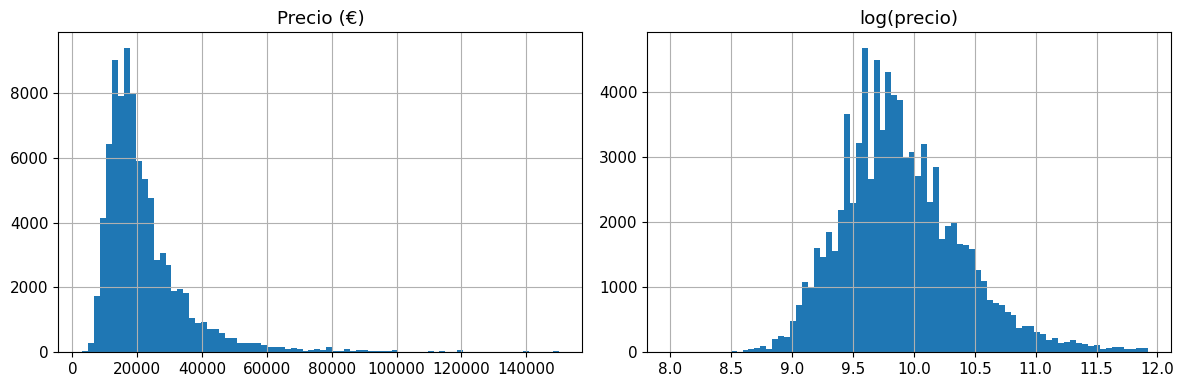

In [51]:
import matplotlib.pyplot as plt

# 1. Estadísticos con las dos colas
print(df_clean["price_eur"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))

# 2. Asimetría: ¿hace falta log?
print("Skew precio:", round(df_clean["price_eur"].skew(), 2))
print("Skew log(precio):", round(np.log(df_clean["price_eur"]).skew(), 2))

# 3. Histogramas lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["price_eur"], bins=80)
axes[0].set_title("Precio (€)")
axes[1].hist(np.log(df_clean["price_eur"]), bins=80)
axes[1].set_title("log(precio)")
plt.tight_layout()
plt.show()

                count     mean      std     min      1%       5%      50%  \
mileage_km    86796.0  74602.9  47504.0  1000.0  3449.6  10000.0  70772.5   
antiguedad    86796.0      4.9      2.6     0.0     0.5      1.2      4.4   
km_anio       86796.0  15947.8   8064.2   117.3  2336.0   4982.4  14830.1   
power_hp      86117.0    154.9     77.8     2.0    69.0     82.0    136.0   
images_count  86796.0     21.3     10.4     1.0     2.0      7.0     21.0   

                   95%       99%       max  skew  nulos  
mileage_km    154095.0  211000.0  758500.0  1.04      0  
antiguedad         9.6      10.6      10.8  0.41      0  
km_anio        30784.7   39810.3   97988.0  1.12      0  
power_hp         306.0     476.0     851.0  2.63    679  
images_count      39.0      50.0      51.0  0.45      0  


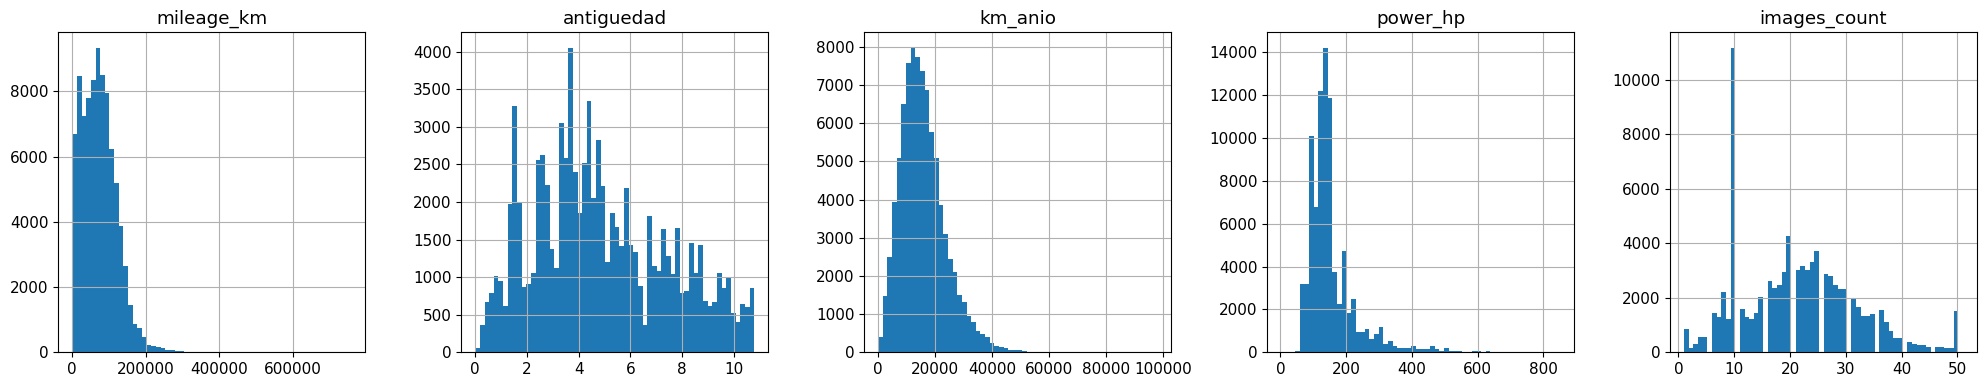

In [52]:
nums = ["mileage_km", "antiguedad", "km_anio", "power_hp", "images_count"]

# Estadísticos + skew
resumen = df_clean[nums].describe(percentiles=[.01, .05, .5, .95, .99]).T.round(1)
resumen["skew"] = df_clean[nums].skew().round(2)
resumen["nulos"] = df_clean[nums].isna().sum()
print(resumen)

# Histogramas
fig, axes = plt.subplots(1, len(nums), figsize=(20, 4))
for ax, col in zip(axes, nums):
    ax.hist(df_clean[col].dropna(), bins=60)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [53]:
# 1. Potencia: ¿cuántos por debajo de 40 CV y qué coches son?
baja = df_clean["power_hp"] < 40
print("Potencia < 40 CV:", baja.sum())
print(df_clean.loc[baja, ["make", "model_group", "fuel", "power_hp"]].value_counts().head(15))

# 2. ¿El pico de 10 fotos depende del lote?
lote = np.where(df_clean["first_seen_at"] < "2026-10-10", "1-9 oct", "10-14 oct")
print(pd.crosstab(lote, df_clean["images_count"] == 10, normalize="index").round(2))

Potencia < 40 CV: 15
make           model_group  fuel              power_hp
Kia            EV4          Eléctrico         5.0         2
Omoda          5            Gasolina          7.0         2
Fiat           Scudo        Diésel            7.0         1
Invicta        D2S          Eléctrico         20.0        1
Honda          Civic        Gasolina          30.0        1
Land Rover     Otros        Diésel            2.0         1
Lynk & Co      1            Híbrido gasolina  4.0         1
Mercedes-Benz  250          Diésel            11.0        1
               GLC          Diésel            2.0         1
Otros          Sonstige     Gasolina          26.0        1
Renault        Twingo       Eléctrico         27.0        1
Subaru         Crosstrek    Híbrido gasolina  16.0        1
Toyota         C-HR         Híbrido gasolina  34.0        1
Name: count, dtype: int64
images_count  False  True 
row_0                     
1-9 oct        0.85   0.15
10-14 oct      0.88   0.12


In [55]:
decisiones.loc[len(decisiones)] = ["images_count fuera del modelo (solo EDA)",
                                   "Describe el anuncio, no el coche; pico en 10 por límites del portal",
                                   "Se excluye de X"]

In [56]:
cats = ["make", "model_group", "fuel", "transmission", "body_grupo", "tipo_hibrido", "provincia"]

# Cardinalidad y categorías raras
for col in cats:
    vc = df_clean[col].value_counts(dropna=False)
    raras = (vc < 100).sum()
    print(f"{col}: {df_clean[col].nunique()} únicas | {raras} con <100 anuncios | "
          f"top1 = {vc.index[0]} ({vc.iloc[0] / len(df_clean):.1%})")

# Concentración: ¿cuántas marcas y modelos cubren el 80 % de los anuncios?
for col in ["make", "model_group"]:
    acum = df_clean[col].value_counts(normalize=True).cumsum()
    print(f"{col}: {(acum < 0.8).sum() + 1} categorías cubren el 80 %")

make: 86 únicas | 47 con <100 anuncios | top1 = Mercedes-Benz (11.3%)
model_group: 664 únicas | 511 con <100 anuncios | top1 = 2008 (2.3%)
fuel: 7 únicas | 1 con <100 anuncios | top1 = Gasolina (45.8%)
transmission: 2 únicas | 0 con <100 anuncios | top1 = Automático (54.5%)
body_grupo: 5 únicas | 1 con <100 anuncios | top1 = nan (38.4%)
tipo_hibrido: 4 únicas | 0 con <100 anuncios | top1 = No híbrido (78.2%)
provincia: 43 únicas | 2 con <100 anuncios | top1 = Madrid (18.6%)
make: 13 categorías cubren el 80 %
model_group: 106 categorías cubren el 80 %


     variable  lim_inf  lim_sup  n_outliers    %
0   price_eur    -4358    44838        5497  6.3
1  mileage_km   -61083   202037        1031  1.2
2  antiguedad       -3       13           0  0.0
3     km_anio    -4652    35204        2075  2.4
4    power_hp       28      248        7896  9.1


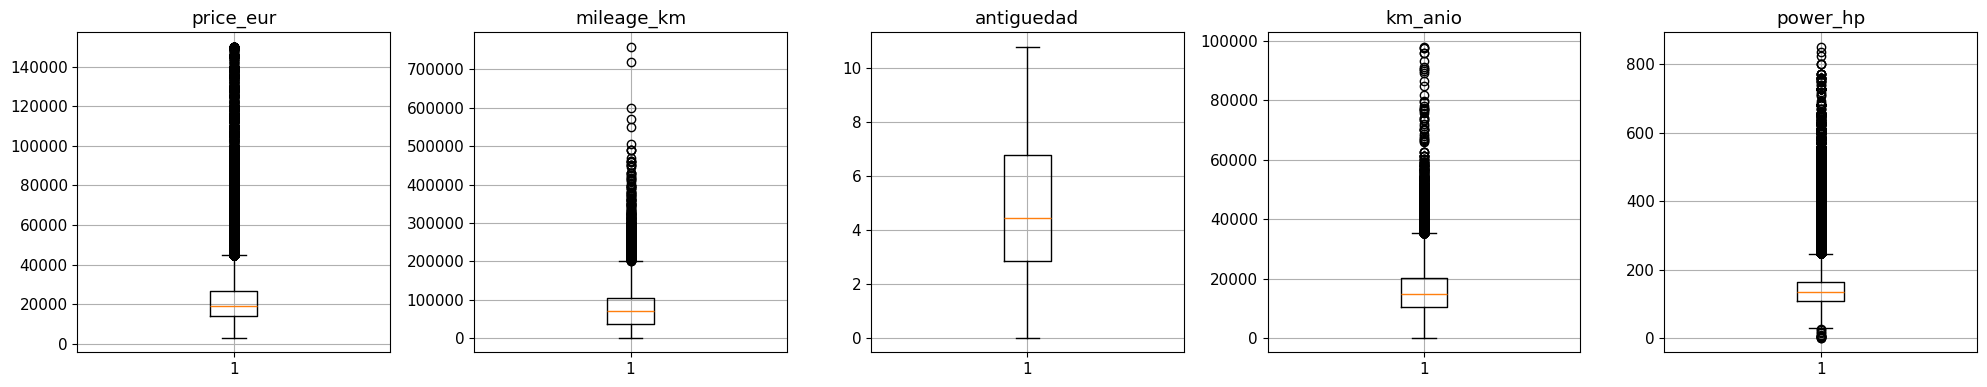

In [57]:
nums = ["price_eur", "mileage_km", "antiguedad", "km_anio", "power_hp"]

filas = []
for col in nums:
    q1, q3 = df_clean[col].quantile([.25, .75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < lim_inf) | (df_clean[col] > lim_sup)).sum()
    filas.append([col, round(lim_inf), round(lim_sup), n_out, round(n_out / len(df_clean) * 100, 1)])

outliers = pd.DataFrame(filas, columns=["variable", "lim_inf", "lim_sup", "n_outliers", "%"])
print(outliers)

# Boxplots
fig, axes = plt.subplots(1, len(nums), figsize=(20, 4))
for ax, col in zip(axes, nums):
    ax.boxplot(df_clean[col].dropna())
    ax.set_title(col)
plt.tight_layout()
plt.show()

              median  count  caida_%  perdida_acum_%
edad_entera                                         
0            31000.0   3256      NaN             0.0
1            25446.0   9323    -17.9            17.9
2            20445.0  10019    -19.7            34.0
3            18900.0  13937     -7.6            39.0
4            19650.0  14172      4.0            36.6
5            17990.0   9452     -8.4            42.0
6            16990.0   6458     -5.6            45.2
7            15490.0   7121     -8.8            50.0
8            14150.0   5859     -8.7            54.4
9            13490.0   4442     -4.7            56.5
10           12199.0   2757     -9.6            60.6
Spearman: rho = -0.383, p = 0.00e+00
R² lineal: 0.072 | R² log(precio): 0.140


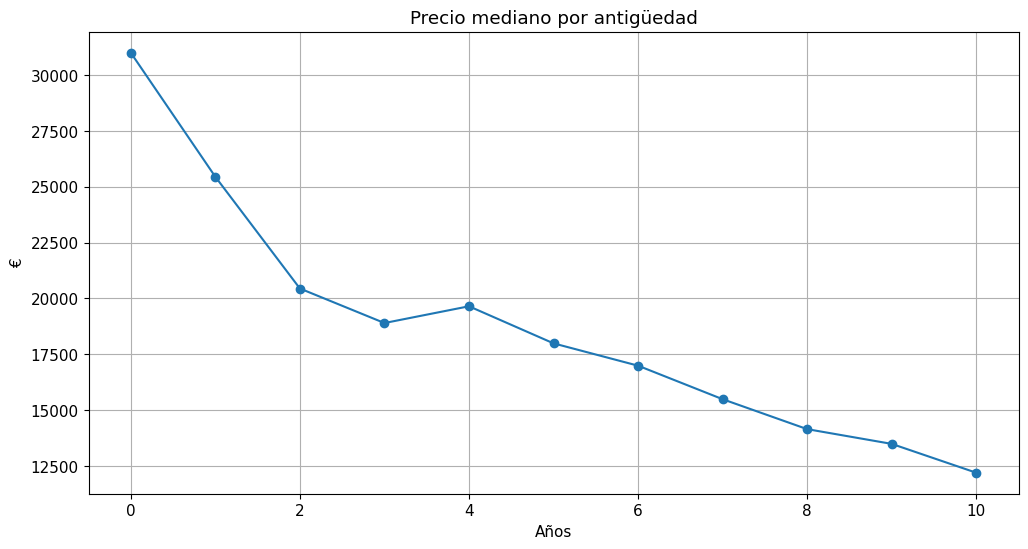

In [58]:
from scipy import stats

# 1. Mediana por año de antigüedad
df_clean["edad_entera"] = df_clean["antiguedad"].astype(int)
dep = df_clean.groupby("edad_entera")["price_eur"].agg(["median", "count"])
dep["caida_%"] = (dep["median"].pct_change() * 100).round(1)
dep["perdida_acum_%"] = ((1 - dep["median"] / dep["median"].iloc[0]) * 100).round(1)
print(dep)

# 2. Spearman
rho, p = stats.spearmanr(df_clean["antiguedad"], df_clean["price_eur"])
print(f"Spearman: rho = {rho:.3f}, p = {p:.2e}")

# 3. ¿Lineal o exponencial? R² de cada ajuste simple
r_lin = stats.linregress(df_clean["antiguedad"], df_clean["price_eur"]).rvalue ** 2
r_log = stats.linregress(df_clean["antiguedad"], np.log(df_clean["price_eur"])).rvalue ** 2
print(f"R² lineal: {r_lin:.3f} | R² log(precio): {r_log:.3f}")

# Gráfico
dep["median"].plot(marker="o", title="Precio mediano por antigüedad")
plt.xlabel("Años"); plt.ylabel("€"); plt.show()

df_clean = df_clean.drop(columns="edad_entera")

                   median  count
fuel                            
Gas               14490.0    733
Gasolina          15990.0  39734
Diésel            19990.0  24577
Híbrido gasolina  22990.0  18522
Eléctrico         28890.0   2801
Otros             33500.0     67
Híbrido diésel    44900.0    362
Kruskal-Wallis: H = 10365, p = 0.00e+00
tramo_edad            0-2      3-5      6-8     9-10
fuel                                                
Diésel            40472.0  23490.0  18500.0  14815.0
Eléctrico         35446.0  27445.0  18990.0  15995.0
Gas               19490.0  13990.0  11905.0  10790.0
Gasolina          20445.0  16590.0  14900.0  11990.0
Híbrido diésel    57900.0  41500.0  39988.0  20250.0
Híbrido gasolina  29082.0  22199.0  19990.0  18370.0
Otros             50700.0  18350.0  13498.0   5900.0


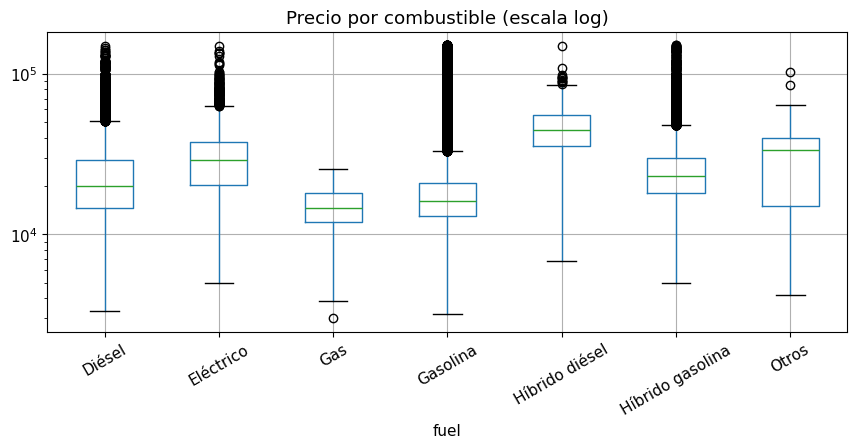

In [59]:
# 1. Mediana y tamaño por combustible
print(df_clean.groupby("fuel")["price_eur"].agg(["median", "count"]).sort_values("median"))

# 2. Kruskal-Wallis (precio asimétrico → no paramétrico)
grupos = [g["price_eur"].values for _, g in df_clean.groupby("fuel")]
h, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H = {h:.0f}, p = {p:.2e}")

# 3. Control básico por edad: mediana por combustible en cada tramo de antigüedad
df_clean["tramo_edad"] = pd.cut(df_clean["antiguedad"], bins=[0, 2, 5, 8, 11],
                                labels=["0-2", "3-5", "6-8", "9-10"], include_lowest=True)
tabla = df_clean.pivot_table(index="fuel", columns="tramo_edad", values="price_eur",
                             aggfunc="median", observed=True).round(0)
print(tabla)

# 4. Boxplot de log(precio)
df_clean.boxplot(column="price_eur", by="fuel", figsize=(10, 4), rot=30)
plt.yscale("log"); plt.suptitle(""); plt.title("Precio por combustible (escala log)"); plt.show()

df_clean = df_clean.drop(columns="tramo_edad")

In [60]:
df_clean["tramo_edad"] = pd.cut(df_clean["antiguedad"], bins=[0, 2, 5, 8, 11],
                                labels=["0-2", "3-5", "6-8", "9-10"], include_lowest=True)

# Mediana y nº de anuncios por modelo × tramo × combustible (solo diésel y gasolina)
sub = df_clean[df_clean["fuel"].isin(["Diésel", "Gasolina"])]
g = sub.groupby(["model_group", "tramo_edad", "fuel"], observed=True)["price_eur"].agg(["median", "count"])
g = g[g["count"] >= 20].reset_index()          # solo celdas con datos suficientes

# Pasar a columnas: una fila por modelo × tramo con ambos combustibles
pares = g.pivot_table(index=["model_group", "tramo_edad"], columns="fuel", values="median", observed=True).dropna()
pares["ratio_diesel_vs_gasolina"] = pares["Diésel"] / pares["Gasolina"]

print("Pares modelo × tramo comparables:", len(pares))
print("Mediana del ratio:", round(pares["ratio_diesel_vs_gasolina"].median(), 3))
print(pares.groupby("tramo_edad", observed=True)["ratio_diesel_vs_gasolina"].median().round(3))

# Test: ¿el ratio es distinto de 1? (Wilcoxon sobre log-ratio)
stat, p = stats.wilcoxon(np.log(pares["ratio_diesel_vs_gasolina"]))
print(f"Wilcoxon: p = {p:.2e}")

df_clean = df_clean.drop(columns="tramo_edad")

Pares modelo × tramo comparables: 162
Mediana del ratio: 0.984
tramo_edad
0-2     0.986
3-5     1.006
6-8     0.974
9-10    0.947
Name: ratio_diesel_vs_gasolina, dtype: float64
Wilcoxon: p = 2.42e-02


In [61]:
decisiones.loc[len(decisiones)] = [
    "H2 contrastada con comparación pareada (modelo × edad)",
    "Agregado sesgado por composición (diésel = coches grandes)",
    "162 pares; diésel −1,6 % (p=0,024); −5,3 % a 9-10 años"]

In [62]:
df_clean["tramo_edad"] = pd.cut(df_clean["antiguedad"], bins=[0, 2, 5, 8, 11],
                                labels=["0-2", "3-5", "6-8", "9-10"], include_lowest=True)

# Precio de referencia: mediana nacional del mismo modelo y tramo de edad
ref = df_clean.groupby(["model_group", "tramo_edad"], observed=True)["price_eur"].transform("median")
df_clean["precio_rel"] = df_clean["price_eur"] / ref        # 1,05 = un 5 % por encima de lo normal

# Índice por provincia (solo provincias con ≥ 300 anuncios)
indice = df_clean.groupby("provincia")["precio_rel"].agg(["median", "count"])
indice = indice[indice["count"] >= 300].sort_values("median")
indice["vs_nacional_%"] = ((indice["median"] - 1) * 100).round(1)
print(indice)

# Test: ¿difiere el precio relativo entre provincias?
grupos = [g["precio_rel"].values for p, g in df_clean.groupby("provincia") if p in indice.index]
h, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H = {h:.0f}, p = {p:.2e}")

df_clean = df_clean.drop(columns=["tramo_edad", "precio_rel"])

                          median  count  vs_nacional_%
provincia                                             
Santa Cruz de Tenerife  0.967732   1995           -3.2
Las Palmas              0.969679   2261           -3.0
Toledo                  0.975593   1103           -2.4
Sevilla                 0.997939   8787           -0.2
Girona                  1.000000    407            0.0
Alicante                1.000000   5062            0.0
Castellón               1.000000    338            0.0
Asturias                1.000000   2327            0.0
Valencia                1.000000   7882            0.0
Zaragoza                1.000000   1113            0.0
Málaga                  1.000000   5667            0.0
Murcia                  1.000000   2838            0.0
Madrid                  1.000000  16187            0.0
Granada                 1.000000    635            0.0
Otras                   1.000324  10707            0.0
Barcelona               1.001685  11262            0.2
Jaén      

In [63]:
decisiones.loc[len(decisiones)] = [
    "H4 con índice de precio relativo (vs mediana nacional modelo × edad)",
    "Evita sesgo de composición entre provincias",
    "Mayoría ±1 %; Canarias −3 %; extremos +3/+6 % ligados a pocos concesionarios"]

              antiguedad  mileage_km  km_anio  power_hp  images_count  \
antiguedad          1.00        0.68    -0.10     -0.04          0.01   
mileage_km          0.68        1.00     0.59     -0.00          0.00   
km_anio            -0.10        0.59     1.00      0.02         -0.01   
power_hp           -0.04       -0.00     0.02      1.00          0.09   
images_count        0.01        0.00    -0.01      0.09          1.00   
price_eur          -0.38       -0.34    -0.07      0.75          0.06   

              price_eur  
antiguedad        -0.38  
mileage_km        -0.34  
km_anio           -0.07  
power_hp           0.75  
images_count       0.06  
price_eur          1.00  


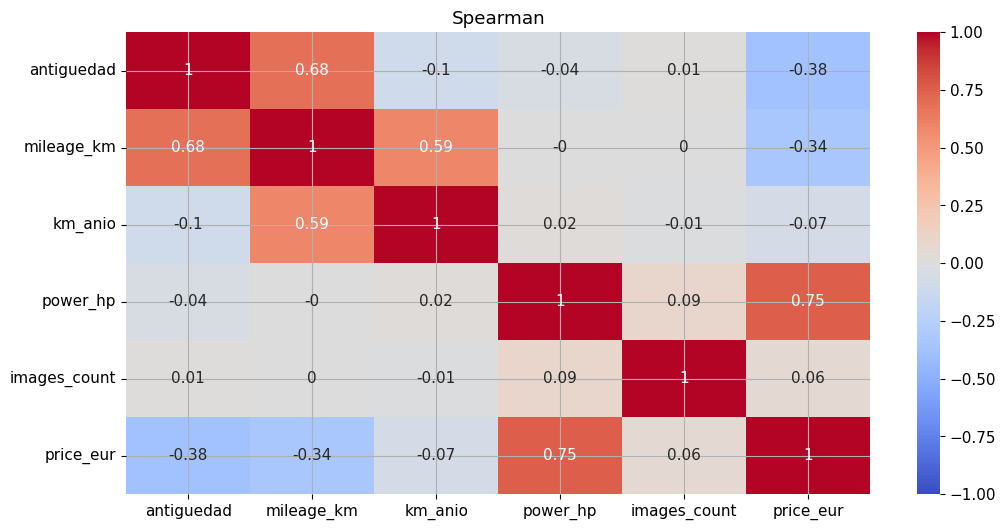

     variable   VIF
1  antiguedad  5.04
2  mileage_km  7.31
3     km_anio  4.39
4    power_hp  1.00


In [64]:
nums = ["antiguedad", "mileage_km", "km_anio", "power_hp", "images_count"]

# 1. Correlación de Spearman (robusta a asimetría)
corr = df_clean[nums + ["price_eur"]].corr(method="spearman").round(2)
print(corr)

import seaborn as sns
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman"); plt.show()

# 2. VIF (solo predictoras numéricas, sin NaN)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(df_clean[["antiguedad", "mileage_km", "km_anio", "power_hp"]].dropna())
vif = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).round(2)
print(vif[vif["variable"] != "const"])

In [65]:
from scipy import stats

# 1. Cambio: 2 grupos → Mann-Whitney
auto = df_clean.loc[df_clean["transmission"] == "Automático", "price_eur"]
man = df_clean.loc[df_clean["transmission"] == "Manual", "price_eur"]
u, p = stats.mannwhitneyu(auto, man)
print(f"Automático {auto.median():.0f} € vs Manual {man.median():.0f} € | p = {p:.2e}")

# 2. Carrocería y tipo de híbrido: 3+ grupos → Kruskal-Wallis
for col in ["body_grupo", "tipo_hibrido"]:
    print(f"\n--- {col} ---")
    print(df_clean.groupby(col)["price_eur"].agg(["median", "count"]).sort_values("median"))
    grupos = [g["price_eur"].values for _, g in df_clean.dropna(subset=[col]).groupby(col)]
    h, p = stats.kruskal(*grupos)
    print(f"Kruskal-Wallis: H = {h:.0f}, p = {p:.2e}")

# 3. Marcas: precio mediano de las 13 que cubren el 80 %
top = df_clean["make"].value_counts().head(13).index
print(df_clean[df_clean["make"].isin(top)].groupby("make")["price_eur"].median().sort_values())

# 4. VIF (si no lo ejecutaste)
print(vif[vif["variable"] != "const"])

Automático 24490 € vs Manual 14470 € | p = 0.00e+00

--- body_grupo ---
                        median  count
body_grupo                           
Turismo                14990.0  23487
Monovolumen/Furgoneta  15990.0   3253
SUV                    18990.0  25381
Otros                  22995.0     32
Deportivo              31494.5   1326
Kruskal-Wallis: H = 5813, p = 0.00e+00

--- tipo_hibrido ---
               median  count
tipo_hibrido                
No híbrido    17490.0  67912
MHEV          19990.0   7428
HEV           23490.0   6921
PHEV          27990.0   4535
Kruskal-Wallis: H = 6194, p = 0.00e+00
make
Citroen          12480.0
Peugeot          14990.0
Ford             15990.0
Renault          15990.0
SEAT             16990.0
Hyundai          17490.0
Kia              17499.5
Skoda            17900.0
Volkswagen       19490.0
Toyota           21900.0
Audi             26490.0
BMW              31500.0
Mercedes-Benz    32982.5
Name: price_eur, dtype: float64
     variable   VIF
1  ant

In [68]:
import os

ruta = r"C:\Users\jhonn\Desktop\NEOLAND\PROYECTO - COCHE\dataset"
os.makedirs(ruta, exist_ok=True)

df_final.to_parquet(os.path.join(ruta, "coches_limpio.parquet"), index=False)
df_final.to_csv(os.path.join(ruta, "coches_limpio.csv"), index=False)
decisiones.to_csv(os.path.join(ruta, "decisiones_limpieza.csv"), index=False)

print(os.listdir(ruta))

['coches_limpio.csv', 'coches_limpio.parquet', 'decisiones_limpieza.csv']
